# Scanorama default vs best - mouse_regulatory_T

Seeds: `0-9`

Primary: paired t-test with BH FDR.


In [1]:
from html.parser import HTMLParser
from io import BytesIO
from pathlib import Path

import matplotlib.font_manager as font_manager
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import nbformat
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import stats

DATASET_NAME = 'mouse_regulatory_T'
NOTEBOOK_DIR = Path('/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/notebooks/optuna_mutimetrics_tests/optuna_scanorama/mouse_regulatory_T')
DEFAULT_NOTEBOOK = NOTEBOOK_DIR / 'Scanorama_mouse_regulatory_T_default_multi_metrics.ipynb'
BEST_NOTEBOOK = NOTEBOOK_DIR / 'Scanorama_mouse_regulatory_T_best_multi_metrics.ipynb'
EXPECTED_SEEDS = tuple(range(10))
EXPECTED_METRICS = ('BAMI', 'CASW', 'SCGRAPHM', 'BRAS', 'KBET', 'CPCR', 'bio_score', 'batch_score', 'joint_score')
ALPHA = 0.05

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()


def display_png(figure):
    buffer = BytesIO()
    figure.savefig(
        buffer,
        format="png",
        dpi=150,
        bbox_inches="tight",
    )
    display(Image(data=buffer.getvalue(), format="png"))
    plt.close(figure)


In [2]:
class ResultTableParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.table_depth = 0
        self.in_cell = False
        self.cell_text = []
        self.row = []
        self.rows = []

    def handle_starttag(self, tag, attrs):
        if tag == "table":
            self.table_depth += 1
        elif self.table_depth and tag in ("th", "td"):
            self.in_cell = True
            self.cell_text = []

    def handle_data(self, data):
        if self.in_cell:
            self.cell_text.append(data)

    def handle_endtag(self, tag):
        if (
            self.table_depth
            and tag in ("th", "td")
            and self.in_cell
        ):
            self.row.append("".join(self.cell_text).strip())
            self.in_cell = False
        elif self.table_depth and tag == "tr":
            if self.row:
                self.rows.append(self.row)
            self.row = []
        elif tag == "table" and self.table_depth:
            self.table_depth -= 1


def html_to_frame(html):
    parser = ResultTableParser()
    parser.feed(html)
    if len(parser.rows) < 2:
        raise ValueError("No result rows found.")

    header = parser.rows[0]
    rows = parser.rows[1:]
    if header and header[0] == "":
        header = header[1:]
        rows = [row[1:] for row in rows]

    frame = pd.DataFrame(rows, columns=header)
    for column in frame.columns:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="raise",
        )
    return frame


def load_results(path):
    notebook = nbformat.read(path, as_version=4)
    cells = [
        cell
        for cell in notebook.cells
        if cell.get("id") == "ten-seed-run"
    ]
    if len(cells) != 1:
        raise ValueError(
            f"Expected one ten-seed-run cell in {path}."
        )

    cell = cells[0]
    if cell.execution_count is None:
        raise ValueError(f"Results are not complete in {path}.")
    if any(
        output.output_type == "error"
        for output in cell.outputs
    ):
        raise ValueError(f"Error output found in {path}.")

    for output in reversed(cell.outputs):
        if output.output_type not in (
            "execute_result",
            "display_data",
        ):
            continue
        html = output.get("data", {}).get("text/html")
        if not html:
            continue
        frame = html_to_frame(html)
        if "seed" in frame.columns:
            frame["seed"] = frame["seed"].astype(int)
            return frame

    raise ValueError(f"No results table found in {path}.")


default_df = load_results(DEFAULT_NOTEBOOK)
best_df = load_results(BEST_NOTEBOOK)

if tuple(default_df.columns) != tuple(best_df.columns):
    raise ValueError("Default and best columns do not match.")
if tuple(default_df["seed"]) != EXPECTED_SEEDS:
    raise ValueError("Default seeds do not match 0-9.")
if tuple(best_df["seed"]) != EXPECTED_SEEDS:
    raise ValueError("Best seeds do not match 0-9.")

metric_columns = tuple(
    column for column in default_df.columns if column != "seed"
)
if metric_columns != EXPECTED_METRICS:
    raise ValueError(
        f"Unexpected metrics: {metric_columns}"
    )

paired_df = default_df.merge(
    best_df,
    on="seed",
    suffixes=("_default", "_best"),
    validate="one_to_one",
)

pd.DataFrame(
    {
        "source": ["default", "best"],
        "notebook": [DEFAULT_NOTEBOOK.name, BEST_NOTEBOOK.name],
        "rows": [len(default_df), len(best_df)],
        "metrics": [len(metric_columns), len(metric_columns)],
    }
)


,source,notebook,rows,metrics
0,default,Scanorama_mouse_regulatory_T_default_multi_met...,10,9
1,best,Scanorama_mouse_regulatory_T_best_multi_metric...,10,9


In [3]:
def mean_ci(values):
    values = np.asarray(values, dtype=float)
    mean = float(np.mean(values))
    margin = float(
        stats.t.ppf(0.975, df=len(values) - 1)
        * stats.sem(values)
    )
    return mean, mean - margin, mean + margin


def paired_cohens_dz(best_values, default_values):
    differences = np.asarray(best_values) - np.asarray(default_values)
    difference_std = float(np.std(differences, ddof=1))
    difference_mean = float(np.mean(differences))
    if np.isclose(difference_std, 0.0):
        if np.isclose(difference_mean, 0.0):
            return 0.0
        return float(np.sign(difference_mean) * np.inf)
    return difference_mean / difference_std


def pooled_cohens_d(best_values, default_values):
    best_values = np.asarray(best_values, dtype=float)
    default_values = np.asarray(default_values, dtype=float)
    pooled_std = float(
        np.sqrt(
            (
                np.var(best_values, ddof=1)
                + np.var(default_values, ddof=1)
            )
            / 2
        )
    )
    mean_difference = float(
        np.mean(best_values) - np.mean(default_values)
    )
    if np.isclose(pooled_std, 0.0):
        if np.isclose(mean_difference, 0.0):
            return 0.0
        return float(np.sign(mean_difference) * np.inf)
    return mean_difference / pooled_std


def safe_wilcoxon(best_values, default_values):
    differences = (
        np.asarray(best_values) - np.asarray(default_values)
    )
    if np.allclose(differences, 0.0):
        return 0.0, 1.0
    result = stats.wilcoxon(
        best_values,
        default_values,
        alternative="two-sided",
    )
    return float(result.statistic), float(result.pvalue)


def safe_paired_ttest(best_values, default_values):
    differences = (
        np.asarray(best_values) - np.asarray(default_values)
    )
    if np.allclose(differences, 0.0):
        return 0.0, 1.0
    result = stats.ttest_rel(best_values, default_values)
    return float(result.statistic), float(result.pvalue)


def bh_adjust(p_values):
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ranked = p_values[order]
    adjusted_ranked = np.minimum.accumulate(
        (
            ranked
            * len(ranked)
            / np.arange(1, len(ranked) + 1)
        )[::-1]
    )[::-1]
    adjusted = np.empty_like(adjusted_ranked)
    adjusted[order] = np.minimum(adjusted_ranked, 1.0)
    return adjusted


rows = []
for metric in metric_columns:
    default_values = paired_df[f"{metric}_default"].to_numpy(
        dtype=float
    )
    best_values = paired_df[f"{metric}_best"].to_numpy(
        dtype=float
    )
    differences = best_values - default_values

    default_mean, default_low, default_high = mean_ci(
        default_values
    )
    best_mean, best_low, best_high = mean_ci(best_values)
    delta_mean, delta_low, delta_high = mean_ci(differences)

    paired_t_stat, paired_t_p = safe_paired_ttest(
        best_values,
        default_values,
    )
    wilcoxon_stat, wilcoxon_p = safe_wilcoxon(
        best_values,
        default_values,
    )
    welch_t = stats.ttest_ind(
        best_values,
        default_values,
        equal_var=False,
    )
    mannwhitney = stats.mannwhitneyu(
        best_values,
        default_values,
        alternative="two-sided",
    )

    rows.append(
        {
            "metric": metric,
            "default_mean": default_mean,
            "default_ci_low": default_low,
            "default_ci_high": default_high,
            "best_mean": best_mean,
            "best_ci_low": best_low,
            "best_ci_high": best_high,
            "mean_delta": delta_mean,
            "delta_ci_low": delta_low,
            "delta_ci_high": delta_high,
            "paired_t_stat": paired_t_stat,
            "paired_t_p": paired_t_p,
            "wilcoxon_stat": wilcoxon_stat,
            "wilcoxon_p": wilcoxon_p,
            "cohens_dz": paired_cohens_dz(
                best_values,
                default_values,
            ),
            "welch_t_p": float(welch_t.pvalue),
            "mannwhitney_p": float(mannwhitney.pvalue),
            "cohens_d": pooled_cohens_d(
                best_values,
                default_values,
            ),
        }
    )

statistics_df = pd.DataFrame(rows).set_index("metric")
statistics_df["paired_t_q"] = bh_adjust(
    statistics_df["paired_t_p"]
)
statistics_df["wilcoxon_q"] = bh_adjust(
    statistics_df["wilcoxon_p"]
)
statistics_df["significant_fdr"] = (
    statistics_df["paired_t_q"] < ALPHA
)
statistics_df["result"] = np.where(
    statistics_df["significant_fdr"],
    np.where(
        statistics_df["mean_delta"] > 0,
        "best significantly higher",
        "best significantly lower",
    ),
    "not significant",
)

result_columns = [
    "default_mean",
    "best_mean",
    "mean_delta",
    "delta_ci_low",
    "delta_ci_high",
    "paired_t_p",
    "paired_t_q",
    "wilcoxon_p",
    "wilcoxon_q",
    "cohens_dz",
    "result",
]
statistics_df[result_columns]


,default_mean,best_mean,mean_delta,delta_ci_low,delta_ci_high,paired_t_p,paired_t_q,wilcoxon_p,wilcoxon_q,cohens_dz,result
metric,,,,,,,,,,,
BAMI,0.669724,0.669280,-0.000444,-0.023082,0.022194,9.655799e-01,9.682683e-01,0.695312,0.769531,-0.014030,not significant
CASW,0.530349,0.530363,0.000014,-0.000002,0.000031,8.532226e-02,1.535801e-01,0.109375,0.196875,0.611127,not significant
SCGRAPHM,0.993115,0.993135,0.000021,0.000016,0.000025,1.523081e-06,6.853863e-06,0.001953,0.005859,3.501447,best significantly higher
BRAS,0.847359,0.854445,0.007086,0.006398,0.007775,2.359516e-09,2.123564e-08,0.001953,0.005859,7.365485,best significantly higher
KBET,0.659062,0.657506,-0.001556,-0.004089,0.000977,1.979720e-01,2.969579e-01,0.193359,0.290039,-0.439527,not significant
CPCR,0.930588,0.932379,0.001791,0.001069,0.002514,3.303604e-04,9.910812e-04,0.001953,0.005859,1.773785,best significantly higher
bio_score,0.731062,0.730926,-0.000136,-0.007681,0.007408,9.682683e-01,9.682683e-01,0.695312,0.769531,-0.012934,not significant
batch_score,0.812336,0.814777,0.002440,0.001334,0.003547,7.489949e-04,1.685239e-03,0.003906,0.008789,1.578018,best significantly higher
joint_score,0.763572,0.764466,0.000894,-0.003546,0.005335,6.594200e-01,8.478257e-01,0.769531,0.769531,0.144096,not significant


In [4]:
statistics_df[
    [
        "welch_t_p",
        "mannwhitney_p",
        "cohens_d",
    ]
]


,welch_t_p,mannwhitney_p,cohens_d
metric,,,
BAMI,0.967192,0.570750,-0.018675
CASW,0.839868,0.791260,0.091682
SCGRAPHM,0.242139,0.307489,0.540990
BRAS,0.000997,0.002202,1.755437
KBET,0.664595,0.677585,-0.197145
CPCR,0.340627,0.273036,0.437758
bio_score,0.969776,0.623176,-0.017202
batch_score,0.250975,0.185877,0.530482
joint_score,0.696786,0.791337,0.177542


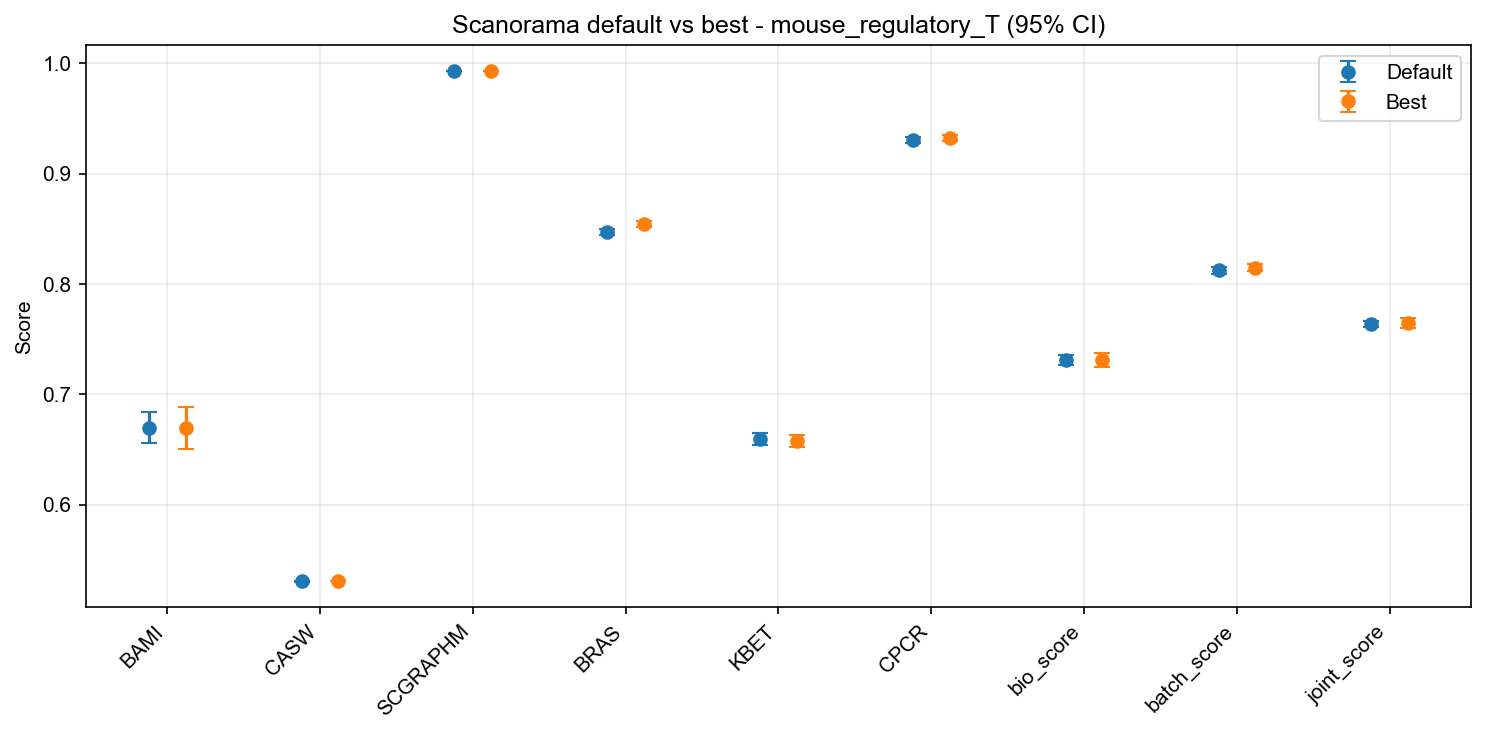

In [5]:
metric_names = list(metric_columns)
x_positions = np.arange(len(metric_columns))
default_means = statistics_df.loc[
    metric_names,
    "default_mean",
].to_numpy()
best_means = statistics_df.loc[
    metric_names,
    "best_mean",
].to_numpy()
default_errors = np.vstack(
    [
        default_means
        - statistics_df.loc[
            metric_names,
            "default_ci_low",
        ].to_numpy(),
        statistics_df.loc[
            metric_names,
            "default_ci_high",
        ].to_numpy()
        - default_means,
    ]
)
best_errors = np.vstack(
    [
        best_means
        - statistics_df.loc[
            metric_names,
            "best_ci_low",
        ].to_numpy(),
        statistics_df.loc[
            metric_names,
            "best_ci_high",
        ].to_numpy()
        - best_means,
    ]
)

figure, axis = plt.subplots(
    figsize=(max(10, len(metric_columns) * 1.05), 5)
)
axis.errorbar(
    x_positions - 0.12,
    default_means,
    yerr=default_errors,
    fmt="o",
    capsize=4,
    label="Default",
)
axis.errorbar(
    x_positions + 0.12,
    best_means,
    yerr=best_errors,
    fmt="o",
    capsize=4,
    label="Best",
)
axis.set_xticks(x_positions)
axis.set_xticklabels(metric_names, rotation=45, ha="right")
axis.set_ylabel("Score")
axis.set_title(
    f"Scanorama default vs best - {DATASET_NAME} (95% CI)"
)
axis.grid(alpha=0.25)
axis.legend()
figure.tight_layout()
display_png(figure)


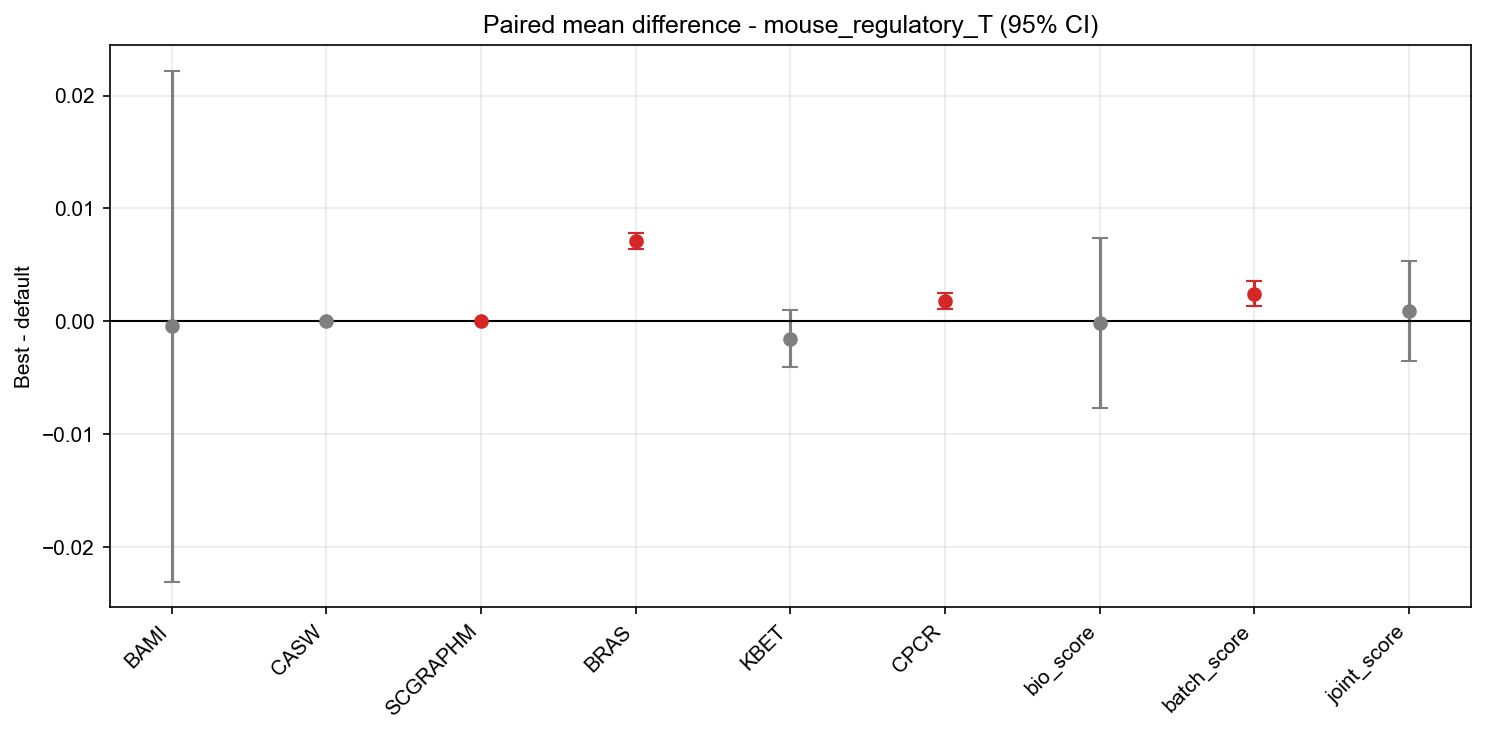

In [6]:
delta_means = statistics_df.loc[
    metric_names,
    "mean_delta",
].to_numpy()
delta_errors = np.vstack(
    [
        delta_means
        - statistics_df.loc[
            metric_names,
            "delta_ci_low",
        ].to_numpy(),
        statistics_df.loc[
            metric_names,
            "delta_ci_high",
        ].to_numpy()
        - delta_means,
    ]
)
significant = statistics_df.loc[
    metric_names,
    "significant_fdr",
].to_numpy()
colors = np.where(significant, "tab:red", "tab:gray")

figure, axis = plt.subplots(
    figsize=(max(10, len(metric_columns) * 1.05), 5)
)
for index, color in enumerate(colors):
    axis.errorbar(
        x_positions[index],
        delta_means[index],
        yerr=delta_errors[:, index : index + 1],
        fmt="o",
        color=color,
        ecolor=color,
        capsize=4,
    )
axis.axhline(0.0, color="black", linewidth=1)
axis.set_xticks(x_positions)
axis.set_xticklabels(metric_names, rotation=45, ha="right")
axis.set_ylabel("Best - default")
axis.set_title(
    f"Paired mean difference - {DATASET_NAME} (95% CI)"
)
axis.grid(alpha=0.25)
figure.tight_layout()
display_png(figure)


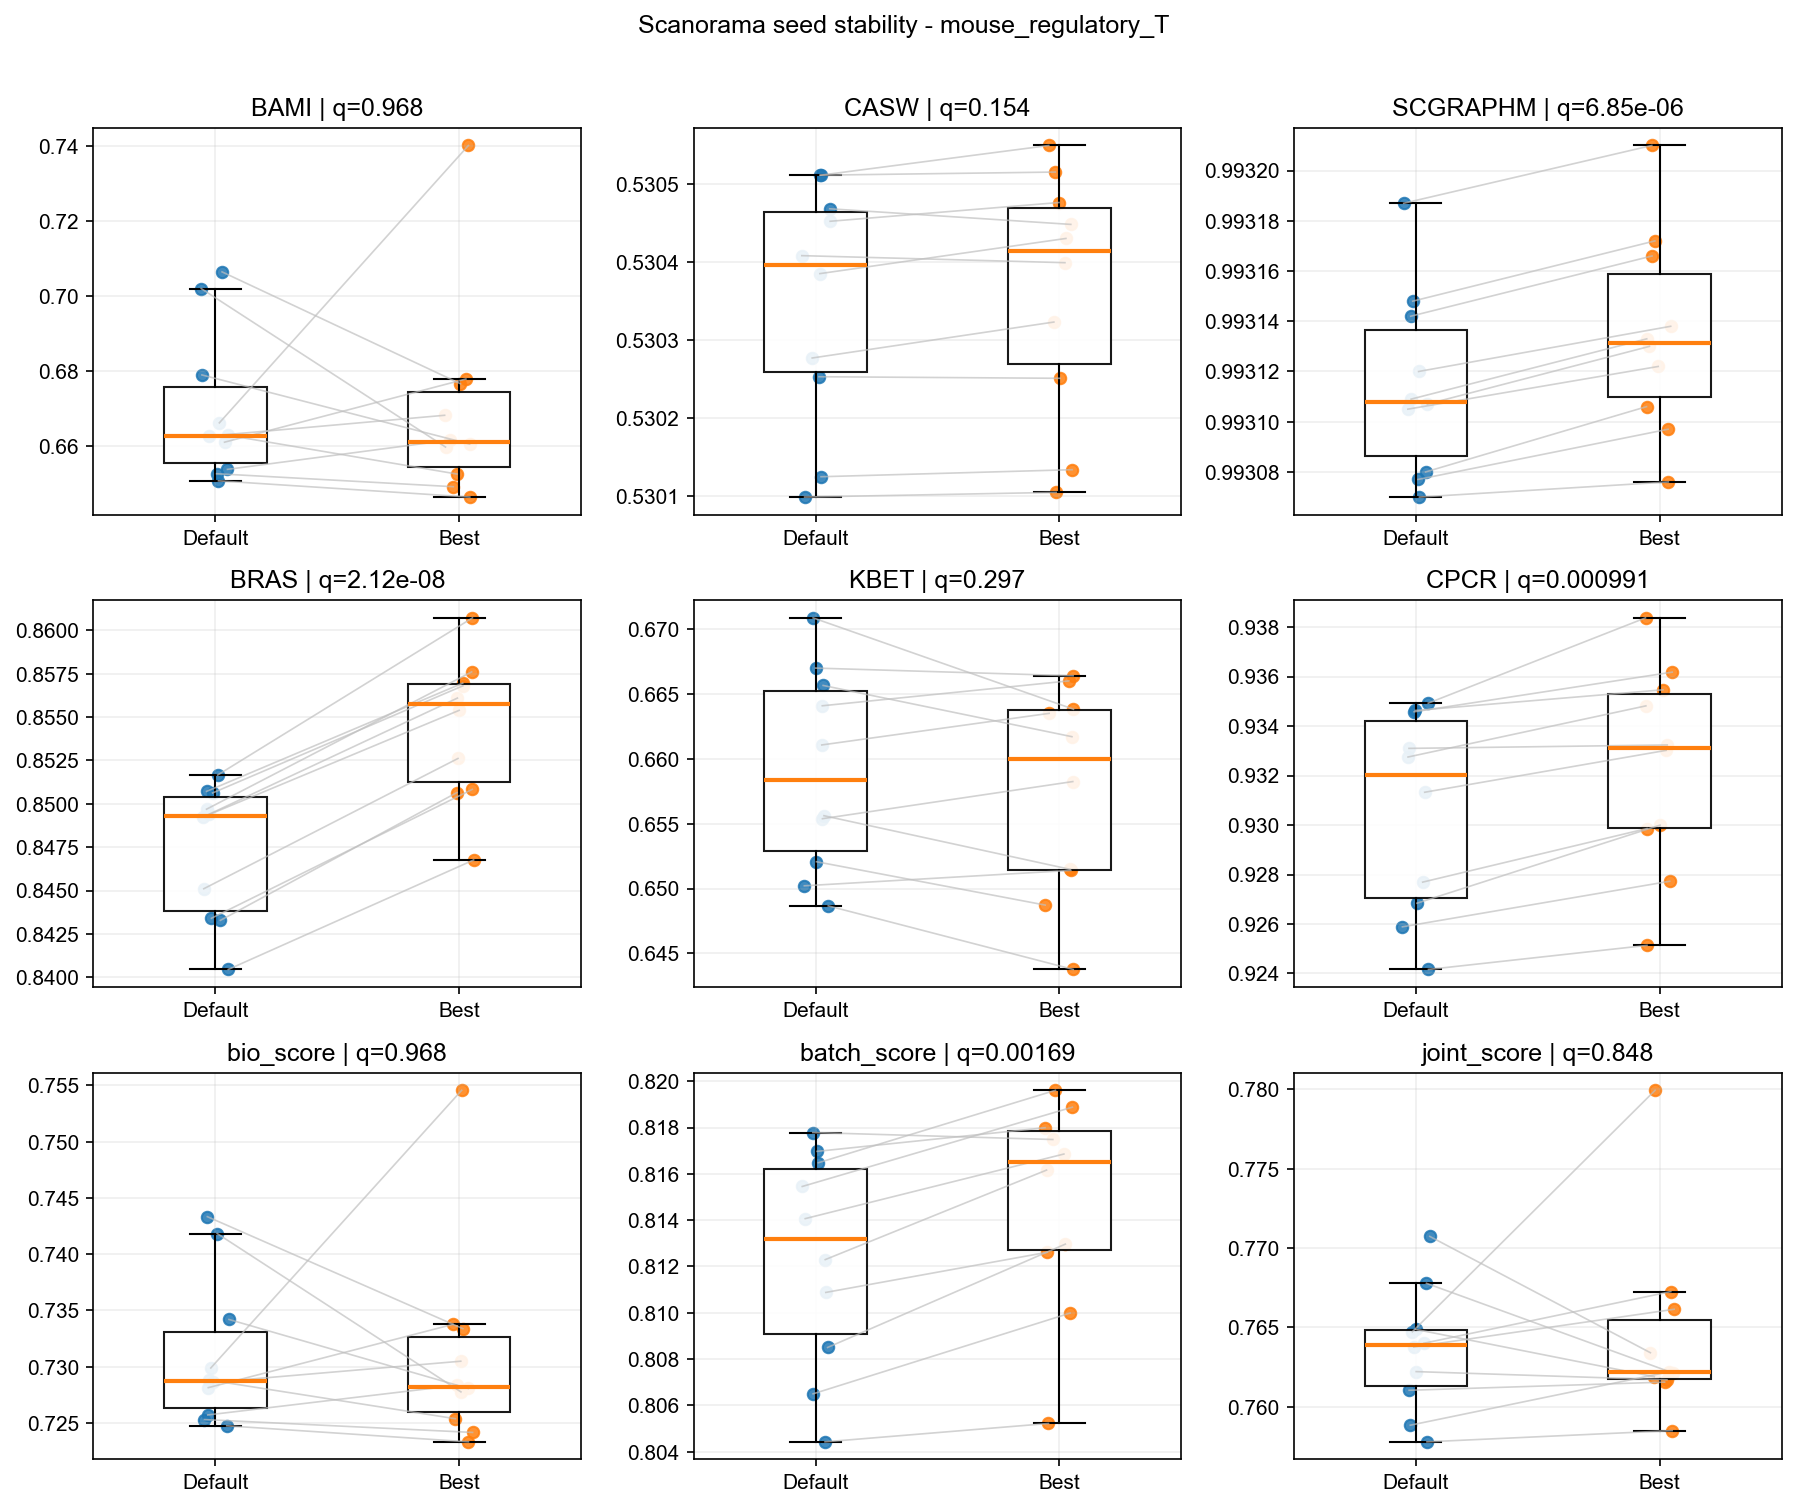

In [7]:
n_columns = 3
n_rows = int(np.ceil(len(metric_columns) / n_columns))
figure, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(12, n_rows * 3.3),
    squeeze=False,
)
random_generator = np.random.default_rng(0)

for axis, metric in zip(axes.flat, metric_columns):
    default_values = paired_df[
        f"{metric}_default"
    ].to_numpy(dtype=float)
    best_values = paired_df[
        f"{metric}_best"
    ].to_numpy(dtype=float)
    default_x = random_generator.uniform(
        -0.06,
        0.06,
        size=len(default_values),
    )
    best_x = 1 + random_generator.uniform(
        -0.06,
        0.06,
        size=len(best_values),
    )

    axis.boxplot(
        [default_values, best_values],
        positions=[0, 1],
        widths=0.42,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "white", "alpha": 0.9},
        medianprops={"linewidth": 2},
    )
    for seed_index in range(len(EXPECTED_SEEDS)):
        axis.plot(
            [default_x[seed_index], best_x[seed_index]],
            [
                default_values[seed_index],
                best_values[seed_index],
            ],
            color="0.75",
            linewidth=0.8,
            alpha=0.7,
        )
    axis.scatter(
        default_x,
        default_values,
        s=30,
        alpha=0.85,
    )
    axis.scatter(
        best_x,
        best_values,
        s=30,
        alpha=0.85,
    )
    q_value = statistics_df.loc[metric, "paired_t_q"]
    axis.set_xticks([0, 1])
    axis.set_xticklabels(["Default", "Best"])
    axis.set_title(f"{metric} | q={q_value:.3g}")
    axis.grid(alpha=0.2)

for axis in axes.flat[len(metric_columns):]:
    axis.set_visible(False)

figure.suptitle(
    f"Scanorama seed stability - {DATASET_NAME}",
    y=1.01,
)
figure.tight_layout()
display_png(figure)


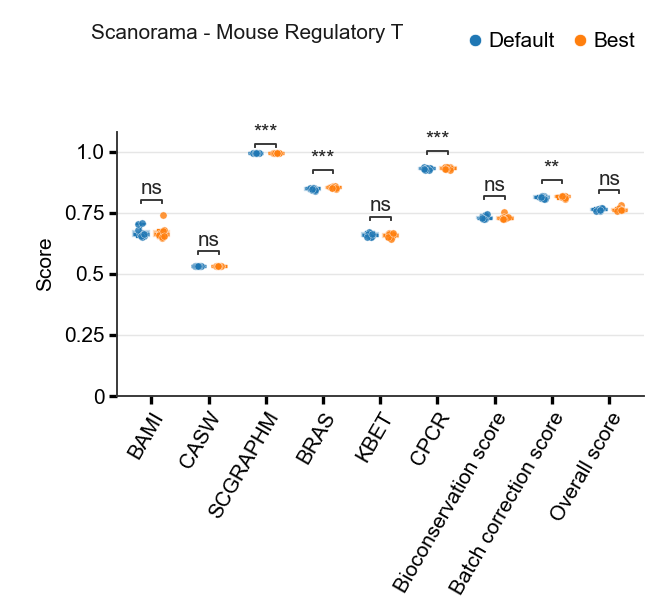

In [8]:
publication_metric_names = list(metric_columns)
publication_metric_label_overrides = {
    "bio_score": "Bioconservation score",
    "batch_score": "Batch correction score",
    "joint_score": "Overall score",
}
publication_metric_labels = [
    publication_metric_label_overrides.get(metric, metric)
    for metric in publication_metric_names
]
publication_centers = np.arange(len(publication_metric_names), dtype=float)
publication_offset = 0.18
publication_width = 0.27
default_positions = publication_centers - publication_offset
best_positions = publication_centers + publication_offset

default_box_values = [
    paired_df[f"{metric}_default"].to_numpy(dtype=float)
    for metric in publication_metric_names
]
best_box_values = [
    paired_df[f"{metric}_best"].to_numpy(dtype=float)
    for metric in publication_metric_names
]
publication_q_values = statistics_df.loc[
    publication_metric_names,
    "paired_t_q",
].to_numpy(dtype=float)


def significance_symbol(q_value):
    if q_value < 0.001:
        return "***"
    if q_value < 0.01:
        return "**"
    if q_value < 0.05:
        return "*"
    return "ns"


default_color, best_color = plt.rcParams[
    "axes.prop_cycle"
].by_key()["color"][:2]
figure, axis = plt.subplots(figsize=(6.5 / 3, 2))
axis.set_axisbelow(True)
axis.grid(
    axis="y",
    color="0.88",
    linewidth=0.35,
    alpha=0.8,
)

default_boxes = axis.boxplot(
    default_box_values,
    positions=default_positions,
    widths=publication_width,
    patch_artist=True,
    showfliers=False,
    manage_ticks=False,
    boxprops={
        "facecolor": default_color,
        "edgecolor": default_color,
        "linewidth": 0.55,
        "alpha": 0.28,
    },
    medianprops={"color": default_color, "linewidth": 0.80},
    whiskerprops={"color": default_color, "linewidth": 0.55},
    capprops={"color": default_color, "linewidth": 0.55},
)
best_boxes = axis.boxplot(
    best_box_values,
    positions=best_positions,
    widths=publication_width,
    patch_artist=True,
    showfliers=False,
    manage_ticks=False,
    boxprops={
        "facecolor": best_color,
        "edgecolor": best_color,
        "linewidth": 0.55,
        "alpha": 0.28,
    },
    medianprops={"color": best_color, "linewidth": 0.80},
    whiskerprops={"color": best_color, "linewidth": 0.55},
    capprops={"color": best_color, "linewidth": 0.55},
)

random_generator = np.random.default_rng(0)
for index, (default_values, best_values) in enumerate(
    zip(default_box_values, best_box_values)
):
    shared_jitter = random_generator.uniform(
        -0.055,
        0.055,
        size=len(default_values),
    )
    axis.scatter(
        default_positions[index] + shared_jitter,
        default_values,
        s=3,
        facecolor=default_color,
        edgecolor="white",
        linewidth=0.10,
        alpha=0.82,
        zorder=3,
    )
    axis.scatter(
        best_positions[index] + shared_jitter,
        best_values,
        s=3,
        facecolor=best_color,
        edgecolor="white",
        linewidth=0.10,
        alpha=0.82,
        zorder=3,
    )

# Paired t-test q-values after BH/FDR correction.
for center, default_values, best_values, q_value in zip(
    publication_centers,
    default_box_values,
    best_box_values,
    publication_q_values,
):
    bracket_y = min(
        max(float(np.max(default_values)), float(np.max(best_values))) + 0.050,
        1.020,
    )
    bracket_height = 0.012
    axis.plot(
        [
            center - publication_offset,
            center - publication_offset,
            center + publication_offset,
            center + publication_offset,
        ],
        [
            bracket_y,
            bracket_y + bracket_height,
            bracket_y + bracket_height,
            bracket_y,
        ],
        color="0.20",
        linewidth=0.45,
        clip_on=False,
        zorder=4,
    )
    axis.text(
        center,
        bracket_y + bracket_height + 0.006,
        significance_symbol(q_value),
        color="0.15",
        ha="center",
        va="bottom",
        fontsize=5,
        zorder=5,
    )

axis.set_xlim(-0.6, len(publication_metric_names) - 0.4)
axis.set_ylim(0.0, 1.08)
axis.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])
axis.set_yticklabels(["0", "0.25", "0.5", "0.75", "1.0"], fontsize=5)
axis.set_ylabel("Score", fontsize=5, labelpad=2)
axis.set_xticks(publication_centers)
axis.set_xticklabels(
    publication_metric_labels,
    rotation=60,
    ha="right",
    rotation_mode="anchor",
    fontsize=5,
)
axis.tick_params(
    axis="both",
    which="major",
    width=0.8,
    length=2,
    labelsize=5,
    pad=1,
)
for spine_name in ("left", "bottom"):
    axis.spines[spine_name].set_linewidth(0.45)
    axis.spines[spine_name].set_color("0.20")
axis.spines["top"].set_visible(False)
axis.spines["right"].set_visible(False)

figure.text(
    0.38,
    0.96,
    "Scanorama - Mouse Regulatory T",
    color="0.10",
    ha="center",
    va="top",
    fontsize=5,
)
legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=default_color,
        markeredgecolor="white",
        markeredgewidth=0.20,
        markersize=3,
        label="Default",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor=best_color,
        markeredgecolor="white",
        markeredgewidth=0.20,
        markersize=3,
        label="Best",
    ),
]
figure.legend(
    handles=legend_handles,
    loc="upper right",
    bbox_to_anchor=(0.99, 0.96),
    frameon=False,
    ncol=2,
    fontsize=5,
    handlelength=0.8,
    handletextpad=0.25,
    columnspacing=0.8,
    borderaxespad=0,
)
figure.subplots_adjust(
    left=0.18,
    right=0.99,
    bottom=0.34,
    top=0.78,
)

publication_buffer = BytesIO()
figure.savefig(
    publication_buffer,
    format="png",
    dpi=300,
    facecolor="white",
)
display(Image(data=publication_buffer.getvalue(), format="png"))
plt.close(figure)


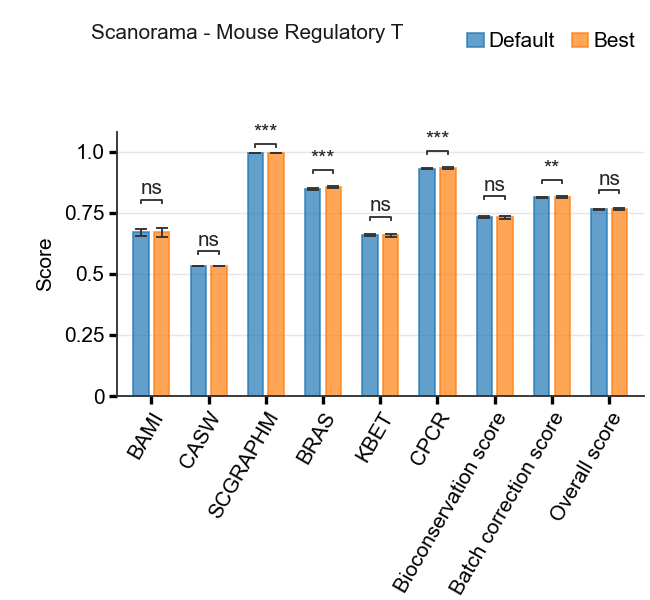

In [9]:
bar_width = 0.27
bar_default_positions = publication_centers - publication_offset
bar_best_positions = publication_centers + publication_offset

bar_default_means = statistics_df.loc[
    publication_metric_names,
    "default_mean",
].to_numpy(dtype=float)
bar_best_means = statistics_df.loc[
    publication_metric_names,
    "best_mean",
].to_numpy(dtype=float)
bar_default_errors = np.vstack(
    [
        bar_default_means
        - statistics_df.loc[
            publication_metric_names,
            "default_ci_low",
        ].to_numpy(dtype=float),
        statistics_df.loc[
            publication_metric_names,
            "default_ci_high",
        ].to_numpy(dtype=float)
        - bar_default_means,
    ]
)
bar_best_errors = np.vstack(
    [
        bar_best_means
        - statistics_df.loc[
            publication_metric_names,
            "best_ci_low",
        ].to_numpy(dtype=float),
        statistics_df.loc[
            publication_metric_names,
            "best_ci_high",
        ].to_numpy(dtype=float)
        - bar_best_means,
    ]
)

bar_figure, bar_axis = plt.subplots(figsize=(6.5 / 3, 2))
bar_axis.set_axisbelow(True)
bar_axis.grid(
    axis="y",
    color="0.88",
    linewidth=0.35,
    alpha=0.8,
)

bar_error_style = {
    "ecolor": "0.20",
    "elinewidth": 0.45,
    "capsize": 1.5,
    "capthick": 0.45,
}
default_bars = bar_axis.bar(
    bar_default_positions,
    bar_default_means,
    width=bar_width,
    color=default_color,
    edgecolor=default_color,
    linewidth=0.45,
    alpha=0.70,
    yerr=bar_default_errors,
    error_kw=bar_error_style,
    zorder=2,
)
best_bars = bar_axis.bar(
    bar_best_positions,
    bar_best_means,
    width=bar_width,
    color=best_color,
    edgecolor=best_color,
    linewidth=0.45,
    alpha=0.70,
    yerr=bar_best_errors,
    error_kw=bar_error_style,
    zorder=2,
)

# Paired t-test q-values after BH/FDR correction.
for index, (center, default_values, best_values, q_value) in enumerate(
    zip(
        publication_centers,
        default_box_values,
        best_box_values,
        publication_q_values,
    )
):
    pair_top = max(
        float(np.max(default_values)),
        float(np.max(best_values)),
        bar_default_means[index] + bar_default_errors[1, index],
        bar_best_means[index] + bar_best_errors[1, index],
    )
    bracket_y = min(pair_top + 0.050, 1.020)
    bracket_height = 0.012
    bar_axis.plot(
        [
            center - publication_offset,
            center - publication_offset,
            center + publication_offset,
            center + publication_offset,
        ],
        [
            bracket_y,
            bracket_y + bracket_height,
            bracket_y + bracket_height,
            bracket_y,
        ],
        color="0.20",
        linewidth=0.45,
        clip_on=False,
        zorder=4,
    )
    bar_axis.text(
        center,
        bracket_y + bracket_height + 0.006,
        significance_symbol(q_value),
        color="0.15",
        ha="center",
        va="bottom",
        fontsize=5,
        zorder=5,
    )

bar_axis.set_xlim(-0.6, len(publication_metric_names) - 0.4)
bar_axis.set_ylim(0.0, 1.08)
bar_axis.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])
bar_axis.set_yticklabels(
    ["0", "0.25", "0.5", "0.75", "1.0"],
    fontsize=5,
)
bar_axis.set_ylabel("Score", fontsize=5, labelpad=2)
bar_axis.set_xticks(publication_centers)
bar_axis.set_xticklabels(
    publication_metric_labels,
    rotation=60,
    ha="right",
    rotation_mode="anchor",
    fontsize=5,
)
bar_axis.tick_params(
    axis="both",
    which="major",
    width=0.8,
    length=2,
    labelsize=5,
    pad=1,
)
for spine_name in ("left", "bottom"):
    bar_axis.spines[spine_name].set_linewidth(0.45)
    bar_axis.spines[spine_name].set_color("0.20")
bar_axis.spines["top"].set_visible(False)
bar_axis.spines["right"].set_visible(False)

bar_figure.text(
    0.38,
    0.96,
    "Scanorama - Mouse Regulatory T",
    color="0.10",
    ha="center",
    va="top",
    fontsize=5,
)
bar_figure.legend(
    handles=[default_bars.patches[0], best_bars.patches[0]],
    labels=["Default", "Best"],
    loc="upper right",
    bbox_to_anchor=(0.99, 0.96),
    frameon=False,
    ncol=2,
    fontsize=5,
    handlelength=0.8,
    handletextpad=0.25,
    columnspacing=0.8,
    borderaxespad=0,
)
bar_figure.subplots_adjust(
    left=0.18,
    right=0.99,
    bottom=0.34,
    top=0.78,
)

bar_buffer = BytesIO()
bar_figure.savefig(
    bar_buffer,
    format="png",
    dpi=300,
    facecolor="white",
)
display(Image(data=bar_buffer.getvalue(), format="png"))
plt.close(bar_figure)


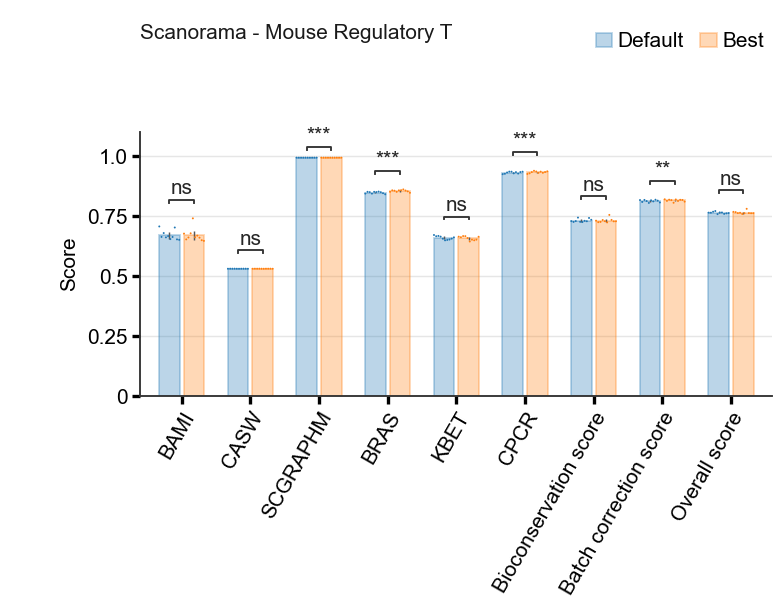

In [10]:
combined_bar_width = 0.30
combined_default_positions = publication_centers - publication_offset
combined_best_positions = publication_centers + publication_offset
combined_point_size = 0.22

combined_figure, combined_axis = plt.subplots(figsize=(6.5 / 2.5, 2))
combined_axis.set_axisbelow(True)
combined_axis.grid(
    axis="y",
    color="0.88",
    linewidth=0.35,
    alpha=0.8,
)

combined_error_style = {
    "ecolor": "0.35",
    "elinewidth": 0.35,
    "capsize": 0.0,
    "capthick": 0.0,
}
combined_default_bars = combined_axis.bar(
    combined_default_positions,
    bar_default_means,
    width=combined_bar_width,
    color=default_color,
    edgecolor=default_color,
    linewidth=0.45,
    alpha=0.30,
    yerr=bar_default_errors,
    error_kw=combined_error_style,
    zorder=2,
)
combined_best_bars = combined_axis.bar(
    combined_best_positions,
    bar_best_means,
    width=combined_bar_width,
    color=best_color,
    edgecolor=best_color,
    linewidth=0.45,
    alpha=0.30,
    yerr=bar_best_errors,
    error_kw=combined_error_style,
    zorder=2,
)

combined_random_generator = np.random.default_rng(0)
for index, (default_values, best_values) in enumerate(
    zip(default_box_values, best_box_values)
):
    combined_jitter = np.linspace(
        -0.145,
        0.145,
        len(default_values),
    )
    combined_random_generator.shuffle(combined_jitter)
    combined_axis.scatter(
        combined_default_positions[index] + combined_jitter,
        default_values,
        s=combined_point_size,
        facecolor=default_color,
        edgecolor="none",
        linewidth=0.0,
        alpha=1.0,
        zorder=3,
    )
    combined_axis.scatter(
        combined_best_positions[index] + combined_jitter,
        best_values,
        s=combined_point_size,
        facecolor=best_color,
        edgecolor="none",
        linewidth=0.0,
        alpha=1.0,
        zorder=3,
    )

# Paired t-test q-values after BH/FDR correction.
for index, (center, default_values, best_values, q_value) in enumerate(
    zip(
        publication_centers,
        default_box_values,
        best_box_values,
        publication_q_values,
    )
):
    combined_pair_top = max(
        float(np.max(default_values)),
        float(np.max(best_values)),
        bar_default_means[index] + bar_default_errors[1, index],
        bar_best_means[index] + bar_best_errors[1, index],
    )
    combined_bracket_y = min(combined_pair_top + 0.065, 1.025)
    combined_bracket_height = 0.012
    combined_axis.plot(
        [
            center - publication_offset,
            center - publication_offset,
            center + publication_offset,
            center + publication_offset,
        ],
        [
            combined_bracket_y,
            combined_bracket_y + combined_bracket_height,
            combined_bracket_y + combined_bracket_height,
            combined_bracket_y,
        ],
        color="0.20",
        linewidth=0.45,
        clip_on=False,
        zorder=4,
    )
    combined_axis.text(
        center,
        combined_bracket_y + combined_bracket_height + 0.006,
        significance_symbol(q_value),
        color="0.15",
        ha="center",
        va="bottom",
        fontsize=5,
        zorder=5,
    )

combined_axis.set_xlim(-0.6, len(publication_metric_names) - 0.4)
combined_axis.set_ylim(0.0, 1.10)
combined_axis.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])
combined_axis.set_yticklabels(
    ["0", "0.25", "0.5", "0.75", "1.0"],
    fontsize=5,
)
combined_axis.set_ylabel("Score", fontsize=5, labelpad=2)
combined_axis.set_xticks(publication_centers)
combined_axis.set_xticklabels(
    publication_metric_labels,
    rotation=60,
    ha="right",
    rotation_mode="anchor",
    fontsize=5,
)
combined_axis.tick_params(
    axis="both",
    which="major",
    width=0.8,
    length=2,
    labelsize=5,
    pad=1,
)
for spine_name in ("left", "bottom"):
    combined_axis.spines[spine_name].set_linewidth(0.45)
    combined_axis.spines[spine_name].set_color("0.20")
combined_axis.spines["top"].set_visible(False)
combined_axis.spines["right"].set_visible(False)

combined_figure.text(
    0.38,
    0.96,
    "Scanorama - Mouse Regulatory T",
    color="0.10",
    ha="center",
    va="top",
    fontsize=5,
)
combined_figure.legend(
    handles=[
        combined_default_bars.patches[0],
        combined_best_bars.patches[0],
    ],
    labels=["Default", "Best"],
    loc="upper right",
    bbox_to_anchor=(0.99, 0.96),
    frameon=False,
    ncol=2,
    fontsize=5,
    handlelength=0.8,
    handletextpad=0.25,
    columnspacing=0.8,
    borderaxespad=0,
)
combined_figure.subplots_adjust(
    left=0.18,
    right=0.99,
    bottom=0.34,
    top=0.78,
)

combined_buffer = BytesIO()
combined_figure.savefig(
    combined_buffer,
    format="png",
    dpi=300,
    facecolor="white",
)
display(Image(data=combined_buffer.getvalue(), format="png"))
plt.close(combined_figure)


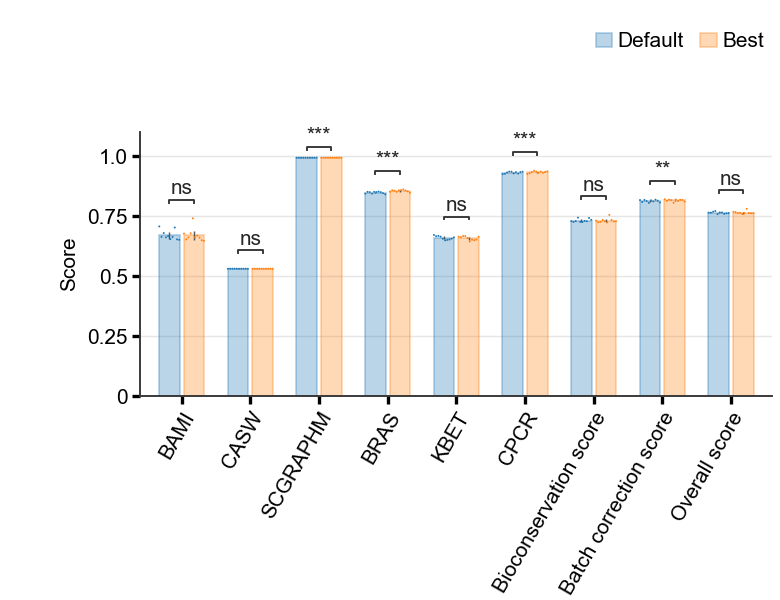

In [11]:
combined_bar_width = 0.30
combined_default_positions = publication_centers - publication_offset
combined_best_positions = publication_centers + publication_offset
combined_point_size = 0.22

combined_figure, combined_axis = plt.subplots(figsize=(6.5 / 2.5, 2))
combined_axis.set_axisbelow(True)
combined_axis.grid(
    axis="y",
    color="0.88",
    linewidth=0.35,
    alpha=0.8,
)

combined_error_style = {
    "ecolor": "0.35",
    "elinewidth": 0.35,
    "capsize": 0.0,
    "capthick": 0.0,
}
combined_default_bars = combined_axis.bar(
    combined_default_positions,
    bar_default_means,
    width=combined_bar_width,
    color=default_color,
    edgecolor=default_color,
    linewidth=0.45,
    alpha=0.30,
    yerr=bar_default_errors,
    error_kw=combined_error_style,
    zorder=2,
)
combined_best_bars = combined_axis.bar(
    combined_best_positions,
    bar_best_means,
    width=combined_bar_width,
    color=best_color,
    edgecolor=best_color,
    linewidth=0.45,
    alpha=0.30,
    yerr=bar_best_errors,
    error_kw=combined_error_style,
    zorder=2,
)

combined_random_generator = np.random.default_rng(0)
for index, (default_values, best_values) in enumerate(
    zip(default_box_values, best_box_values)
):
    combined_jitter = np.linspace(
        -0.145,
        0.145,
        len(default_values),
    )
    combined_random_generator.shuffle(combined_jitter)
    combined_axis.scatter(
        combined_default_positions[index] + combined_jitter,
        default_values,
        s=combined_point_size,
        facecolor=default_color,
        edgecolor="none",
        linewidth=0.0,
        alpha=1.0,
        zorder=3,
    )
    combined_axis.scatter(
        combined_best_positions[index] + combined_jitter,
        best_values,
        s=combined_point_size,
        facecolor=best_color,
        edgecolor="none",
        linewidth=0.0,
        alpha=1.0,
        zorder=3,
    )

# Paired t-test q-values after BH/FDR correction.
for index, (center, default_values, best_values, q_value) in enumerate(
    zip(
        publication_centers,
        default_box_values,
        best_box_values,
        publication_q_values,
    )
):
    combined_pair_top = max(
        float(np.max(default_values)),
        float(np.max(best_values)),
        bar_default_means[index] + bar_default_errors[1, index],
        bar_best_means[index] + bar_best_errors[1, index],
    )
    combined_bracket_y = min(combined_pair_top + 0.065, 1.025)
    combined_bracket_height = 0.012
    combined_axis.plot(
        [
            center - publication_offset,
            center - publication_offset,
            center + publication_offset,
            center + publication_offset,
        ],
        [
            combined_bracket_y,
            combined_bracket_y + combined_bracket_height,
            combined_bracket_y + combined_bracket_height,
            combined_bracket_y,
        ],
        color="0.20",
        linewidth=0.45,
        clip_on=False,
        zorder=4,
    )
    combined_axis.text(
        center,
        combined_bracket_y + combined_bracket_height + 0.006,
        significance_symbol(q_value),
        color="0.15",
        ha="center",
        va="bottom",
        fontsize=5,
        zorder=5,
    )

combined_axis.set_xlim(-0.6, len(publication_metric_names) - 0.4)
combined_axis.set_ylim(0.0, 1.10)
combined_axis.set_yticks([0.0, 0.25, 0.5, 0.75, 1.0])
combined_axis.set_yticklabels(
    ["0", "0.25", "0.5", "0.75", "1.0"],
    fontsize=5,
)
combined_axis.set_ylabel("Score", fontsize=5, labelpad=2)
combined_axis.set_xticks(publication_centers)
combined_axis.set_xticklabels(
    publication_metric_labels,
    rotation=60,
    ha="right",
    rotation_mode="anchor",
    fontsize=5,
)
combined_axis.tick_params(
    axis="both",
    which="major",
    width=0.8,
    length=2,
    labelsize=5,
    pad=1,
)
for spine_name in ("left", "bottom"):
    combined_axis.spines[spine_name].set_linewidth(0.45)
    combined_axis.spines[spine_name].set_color("0.20")
combined_axis.spines["top"].set_visible(False)
combined_axis.spines["right"].set_visible(False)

combined_figure.legend(
    handles=[
        combined_default_bars.patches[0],
        combined_best_bars.patches[0],
    ],
    labels=["Default", "Best"],
    loc="upper right",
    bbox_to_anchor=(0.99, 0.96),
    frameon=False,
    ncol=2,
    fontsize=5,
    handlelength=0.8,
    handletextpad=0.25,
    columnspacing=0.8,
    borderaxespad=0,
)
combined_figure.subplots_adjust(
    left=0.18,
    right=0.99,
    bottom=0.34,
    top=0.78,
)

combined_buffer = BytesIO()
combined_figure.savefig(
    combined_buffer,
    format="png",
    dpi=300,
    facecolor="white",
)
display(Image(data=combined_buffer.getvalue(), format="png"))
plt.close(combined_figure)
